# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** **RAHUL G** &nbsp;&nbsp; **Roll No.:** **1RUA25CSE0366** &nbsp;&nbsp; **Date:** **10/11/2026**

> **Dataset note:** The uploaded assignment contained the notebook but not `heart.csv`. Before running, download the CSV from the Kaggle source above and place it in an `Exercise` folder beside this notebook. The completed code checks this location.

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

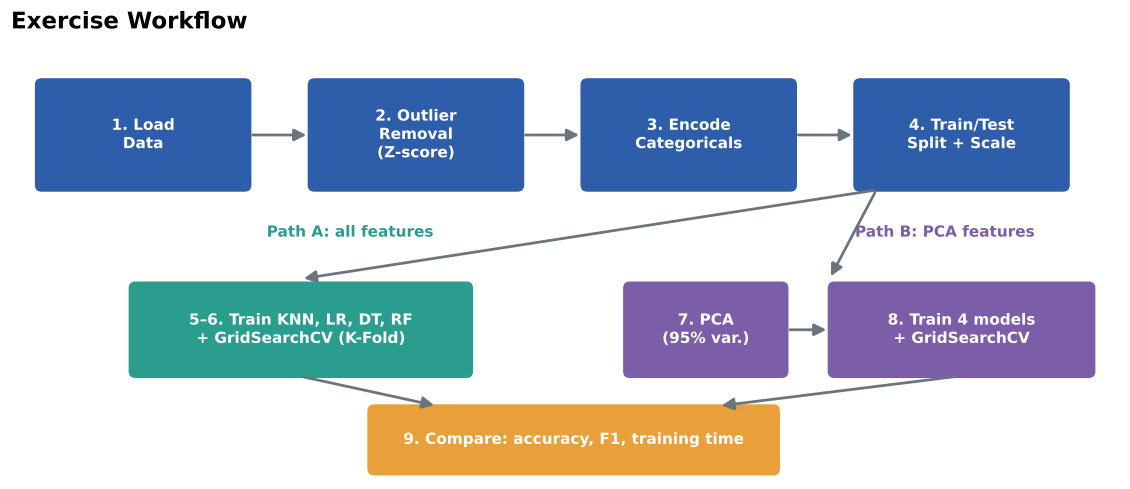

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [22]:
# Import required libraries
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [25]:
# Load heart.csv from the expected Exercise folder or the notebook's current folder.
possible_paths = [
    os.path.join("Exercise", "heart.csv"),
    "heart.csv",
    os.path.join("data", "heart.csv")
]
csv_path = next((path for path in possible_paths if os.path.exists(path)), None)

if csv_path is None:
    raise FileNotFoundError(
        "heart.csv was not found. Download the Heart Failure Prediction Dataset from "
        "https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction "
        "and place heart.csv in an 'Exercise' folder beside this notebook."
    )

df = pd.read_csv("heart.csv")
display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [26]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()
display(df.describe(include="all").T)

Dataset shape: (918, 12)
\nColumn names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usag

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,918.0,NaN,NaN,NaN,132.396514,18.514154,0.0,120.0,130.0,140.0,200.0
Cholesterol,918.0,NaN,NaN,NaN,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,918.0,NaN,NaN,NaN,136.809368,25.460334,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


### 1.3 Check for missing values

In [27]:
print("Missing values per column:")
display(df.isnull().sum())
print("Total missing values:", int(df.isnull().sum().sum()))

Missing values per column:


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

In [28]:
display(df["HeartDisease"].value_counts().rename("count").to_frame())
display((df["HeartDisease"].value_counts(normalize=True) * 100).rename("percentage").to_frame())

,count
HeartDisease,
1,508
0,410


,percentage
HeartDisease,
1,55.337691
0,44.662309


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> **Answer:** The dataset contains 918 records and 12 columns (11 input features and the `HeartDisease` target) in the standard Kaggle version. The text-based columns are `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope`. The standard file has no missing values. Confirm these observations using the shape, data types and missing-value outputs above.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

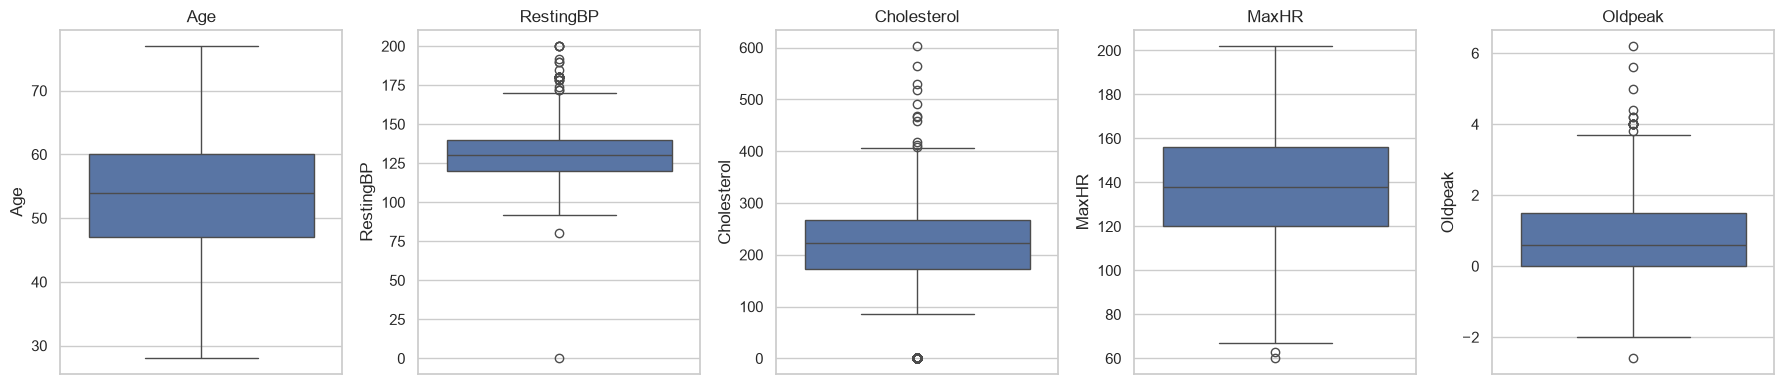

In [29]:
continuous_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, len(continuous_features), figsize=(18, 4))
for ax, col in zip(axes, continuous_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [30]:
# Calculate Z-scores only for the five continuous numerical features.
z_scores = pd.DataFrame(
    np.abs(zscore(df[continuous_features], nan_policy="omit")),
    columns=continuous_features,
    index=df.index
)
display(z_scores.head())

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,1.433140,0.410909,0.825070,1.382928,0.832432
1,0.478484,1.491752,0.171961,0.754157,0.105664
2,1.751359,0.129513,0.770188,1.525138,0.832432
3,0.584556,0.302825,0.139040,1.132156,0.574711
4,0.051881,0.951331,0.034755,0.581981,0.832432


### 2.3 Identify and count the outlier records

In [31]:
# A row is an outlier if ANY selected feature has |z-score| > 3.
outlier_mask = (z_scores > 3).any(axis=1)
outlier_count = int(outlier_mask.sum())
print("Outlier records:", outlier_count)
print("\\nOutlier counts by feature:")
display((z_scores > 3).sum().sort_values(ascending=False).rename("outlier_count").to_frame())

Outlier records: 19
\nOutlier counts by feature:


,outlier_count
RestingBP,8
Oldpeak,7
Cholesterol,3
MaxHR,1
Age,0


### 2.4 Remove the outliers and display the new shape

In [32]:
df_before_outlier_removal = df.copy()
df_clean = df.loc[~outlier_mask].reset_index(drop=True)
print("Shape before removal:", df_before_outlier_removal.shape)
print("Shape after removal:", df_clean.shape)
print("Records removed:", len(df_before_outlier_removal) - len(df_clean))

Shape before removal: (918, 12)
Shape after removal: (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

> **Answer:** The number of removed records is the value printed as `Outlier records` in Task 2.3. A record is removed when at least one of `Age`, `RestingBP`, `Cholesterol`, `MaxHR` or `Oldpeak` has an absolute Z-score greater than 3. The feature with the highest count in the Task 2.3 table contributed the most outliers. The exact counts depend on the dataset file.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [33]:
categorical_features = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
print("Categorical features:", categorical_features)
for col in categorical_features:
    print(f"\\n{col}:")
    print(df_clean[col].unique())

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
\nSex:
<ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
\nChestPainType:
<ArrowStringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
\nRestingECG:
<ArrowStringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
\nExerciseAngina:
<ArrowStringArray>
['N', 'Y']
Length: 2, dtype: str
\nST_Slope:
<ArrowStringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [34]:
# Label encode the two binary categorical features.
df_encoded = df_clean.copy()
label_encoders = {}
for col in ["Sex", "ExerciseAngina"]:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = encoder
    print(f"{col} mapping:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

Sex mapping: {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina mapping: {'N': np.int64(0), 'Y': np.int64(1)}


### 3.3 Apply One-Hot Encoding

In [35]:
# One-hot encode nominal features with more than two categories.
nominal_features = ["ChestPainType", "RestingECG", "ST_Slope"]
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)
print("Shape after one-hot encoding:", df_encoded.shape)

Shape after one-hot encoding: (899, 16)


### 3.4 Display the final encoded dataset

In [36]:
display(df_encoded.head())
print("Final encoded shape:", df_encoded.shape)
print("Encoded columns:", df_encoded.columns.tolist())

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


Final encoded shape: (899, 16)
Encoded columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> **Answer:** `Sex` and `ExerciseAngina` are binary categorical variables, so Label Encoding converts each into two numeric labels. `ChestPainType`, `RestingECG` and `ST_Slope` are nominal variables with more than two categories, so One-Hot Encoding is appropriate because it avoids implying a false numerical order. The final feature count is shown by `df_encoded.shape`; there are 11 original predictors before encoding, and one-hot encoding expands the three nominal columns (with `drop_first=True`).

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [37]:
X = df_encoded.drop(columns=["HeartDisease"])
y = df_encoded["HeartDisease"].astype(int)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (899, 15)
y shape: (899,)


### 4.2 Split into training and testing sets

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training set:", X_train.shape, "Testing set:", X_test.shape)
print("Training target proportions:")
display(y_train.value_counts(normalize=True))
print("Testing target proportions:")
display(y_test.value_counts(normalize=True))

Training set: (719, 15) Testing set: (180, 15)
Training target proportions:


HeartDisease
1    0.546592
0    0.453408
Name: proportion, dtype: float64

Testing target proportions:


HeartDisease
1    0.55
0    0.45
Name: proportion, dtype: float64

### 4.3 Apply feature scaling (fit on training data only)

In [39]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit ONLY on training data
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (719, 15)
Scaled testing shape: (180, 15)


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> **Answer:** I used `StandardScaler` because it transforms each feature using the training-set mean and standard deviation, giving features comparable scales. This is important for KNN distances and Logistic Regression optimisation. If the scaler were fitted before splitting, information about the test-set distribution (its mean and standard deviation) would influence preprocessing. This is data leakage and can make test evaluation less reliable. Fit on `X_train` only, then transform both sets.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [40]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    """Fit a classifier, time fitting, and return test metrics and predictions."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start
    y_pred = model.predict(X_test)
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Training Time (s)": training_time
    }
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(type(model).__name__ + " - Confusion Matrix")
    plt.show()
    return metrics, y_pred

### 5.2 K-Nearest Neighbors

              precision    recall  f1-score   support

           0       0.90      0.85      0.87        81
           1       0.88      0.92      0.90        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



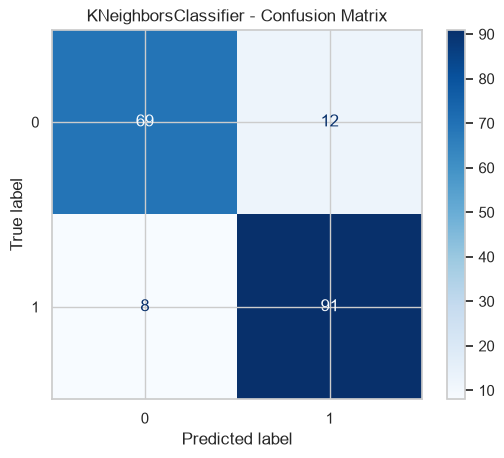

{'Accuracy': 0.8888888888888888, 'Precision': 0.883495145631068, 'Recall': 0.9191919191919192, 'F1-score': 0.900990099009901, 'Training Time (s)': 0.012338200001977384}


In [41]:
# K-Nearest Neighbors with default hyperparameters
knn_default = KNeighborsClassifier()
knn_default_metrics, knn_default_pred = evaluate_model(
    knn_default, X_train_scaled, X_test_scaled, y_train, y_test
)
print(knn_default_metrics)

### 5.3 Logistic Regression

              precision    recall  f1-score   support

           0       0.87      0.84      0.86        81
           1       0.87      0.90      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



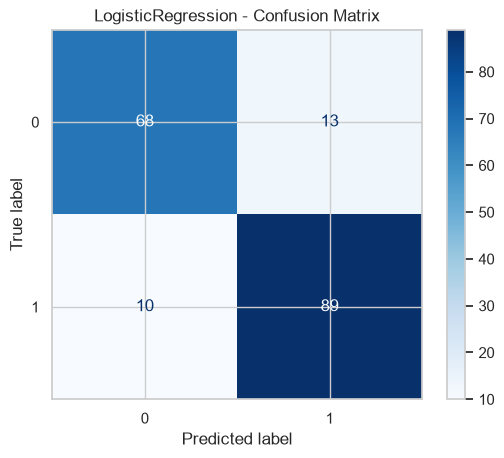

{'Accuracy': 0.8722222222222222, 'Precision': 0.8725490196078431, 'Recall': 0.898989898989899, 'F1-score': 0.8855721393034826, 'Training Time (s)': 0.05213329999969574}


In [42]:
# Logistic Regression with default hyperparameters
lr_default = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
lr_default_metrics, lr_default_pred = evaluate_model(
    lr_default, X_train_scaled, X_test_scaled, y_train, y_test
)
print(lr_default_metrics)

### 5.4 Decision Tree

              precision    recall  f1-score   support

           0       0.80      0.79      0.80        81
           1       0.83      0.84      0.83        99

    accuracy                           0.82       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180



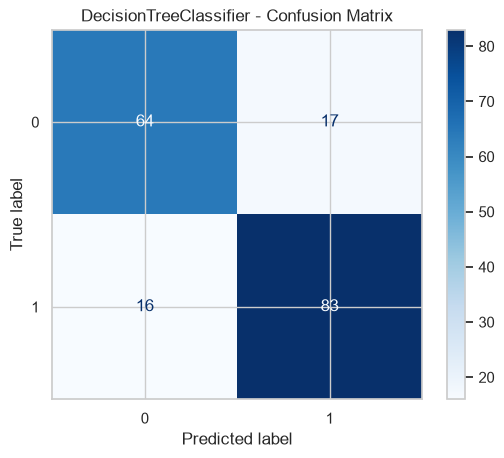

{'Accuracy': 0.8166666666666667, 'Precision': 0.83, 'Recall': 0.8383838383838383, 'F1-score': 0.8341708542713567, 'Training Time (s)': 0.02531930000259308}


In [43]:
# Decision Tree with default hyperparameters
dt_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_default_metrics, dt_default_pred = evaluate_model(
    dt_default, X_train_scaled, X_test_scaled, y_train, y_test
)
print(dt_default_metrics)

### 5.5 Random Forest

              precision    recall  f1-score   support

           0       0.88      0.83      0.85        81
           1       0.87      0.91      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



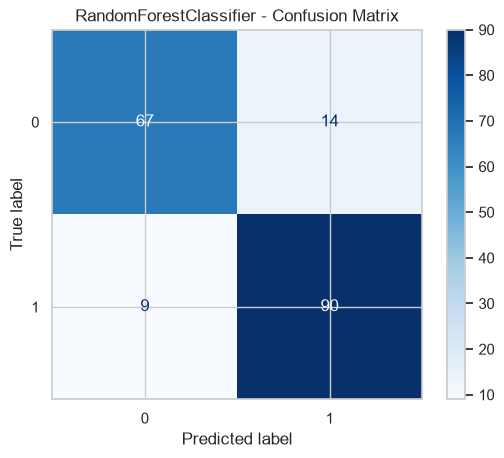

{'Accuracy': 0.8722222222222222, 'Precision': 0.8653846153846154, 'Recall': 0.9090909090909091, 'F1-score': 0.8866995073891626, 'Training Time (s)': 0.6490425000010873}


In [44]:
# Random Forest with default hyperparameters
rf_default = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_default_metrics, rf_default_pred = evaluate_model(
    rf_default, X_train_scaled, X_test_scaled, y_train, y_test
)
print(rf_default_metrics)

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training Time (s)
KNN,0.888889,0.883495,0.919192,0.900990,0.012338
Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.052133
Decision Tree,0.816667,0.830000,0.838384,0.834171,0.025319
Random Forest,0.872222,0.865385,0.909091,0.886700,0.649043


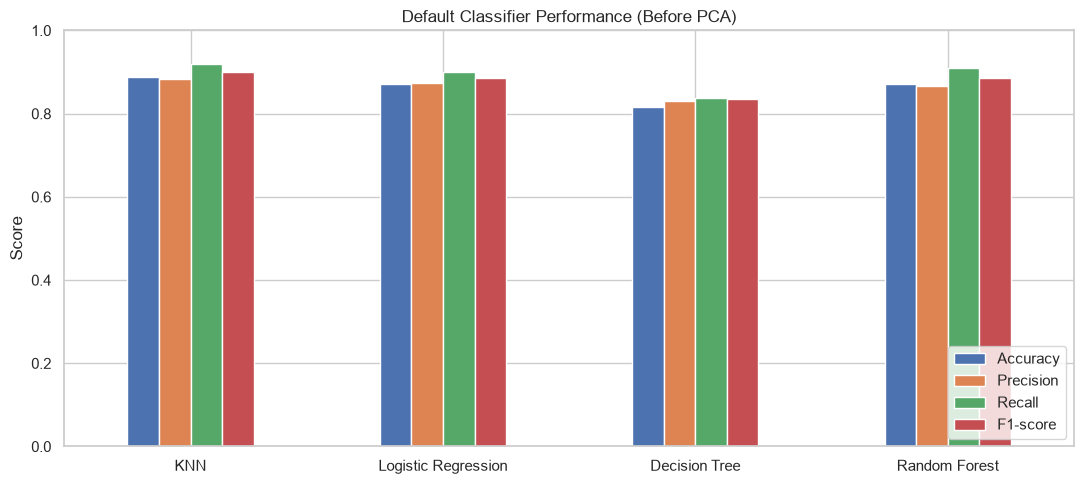

In [45]:
default_results = pd.DataFrame({
    "KNN": knn_default_metrics,
    "Logistic Regression": lr_default_metrics,
    "Decision Tree": dt_default_metrics,
    "Random Forest": rf_default_metrics
}).T
display(default_results)
default_results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0
)
plt.ylabel("Score")
plt.title("Default Classifier Performance (Before PCA)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> **Answer:** The model with the highest `Accuracy` in the Task 5 comparison table is the highest-accuracy default model for this particular train/test split. Accuracy alone is not sufficient for a medical screening task. Recall should receive strong attention because a false negative means a patient with heart disease is missed. Precision also matters because false positives can cause unnecessary follow-up tests. The confusion matrix and all metrics should therefore be considered together.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = "f1"

param_grids = {
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "Decision Tree": {
        "max_depth": [None, 3, 5, 8, 12],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
        "max_features": ["sqrt", "log2"]
    }
}

model_factories = {
    "KNN": KNeighborsClassifier,
    "Logistic Regression": lambda: LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
}

### 6.2 Tune KNN

In [47]:
# Grid search for KNN
knn_grid = GridSearchCV(
    model_factories["KNN"](),
    param_grids["KNN"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
knn_grid.fit(X_train_scaled, y_train)
print("Best parameters:", knn_grid.best_params_)
print("Best mean CV F1-score:", knn_grid.best_score_)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best mean CV F1-score: 0.8932133072665671


### 6.3 Tune Logistic Regression

In [48]:
# Grid search for Logistic Regression
lr_grid = GridSearchCV(
    model_factories["Logistic Regression"](),
    param_grids["Logistic Regression"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
lr_grid.fit(X_train_scaled, y_train)
print("Best parameters:", lr_grid.best_params_)
print("Best mean CV F1-score:", lr_grid.best_score_)

Best parameters: {'C': 0.1, 'solver': 'lbfgs'}
Best mean CV F1-score: 0.8812414880819389


### 6.4 Tune Decision Tree

In [49]:
# Grid search for Decision Tree
dt_grid = GridSearchCV(
    model_factories["Decision Tree"](),
    param_grids["Decision Tree"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
dt_grid.fit(X_train_scaled, y_train)
print("Best parameters:", dt_grid.best_params_)
print("Best mean CV F1-score:", dt_grid.best_score_)

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best mean CV F1-score: 0.8492476134117917


### 6.5 Tune Random Forest

In [50]:
# Grid search for Random Forest
rf_grid = GridSearchCV(
    model_factories["Random Forest"](),
    param_grids["Random Forest"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
rf_grid.fit(X_train_scaled, y_train)
print("Best parameters:", rf_grid.best_params_)
print("Best mean CV F1-score:", rf_grid.best_score_)

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best mean CV F1-score: 0.8896664281533658


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

              precision    recall  f1-score   support

           0       0.90      0.86      0.88        81
           1       0.89      0.92      0.91        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



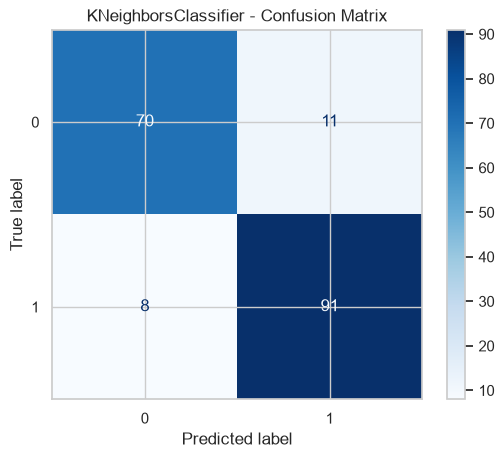

              precision    recall  f1-score   support

           0       0.88      0.84      0.86        81
           1       0.87      0.91      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.87      0.88       180
weighted avg       0.88      0.88      0.88       180



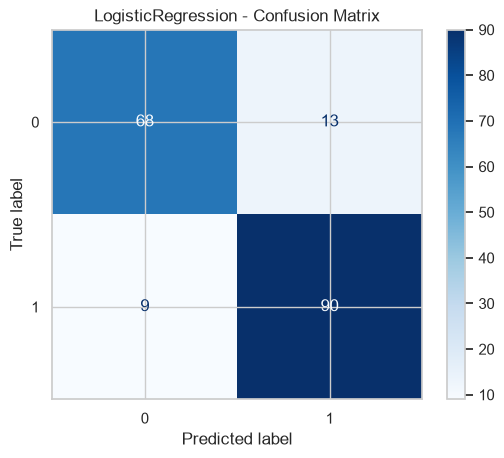

              precision    recall  f1-score   support

           0       0.77      0.86      0.81        81
           1       0.88      0.79      0.83        99

    accuracy                           0.82       180
   macro avg       0.82      0.83      0.82       180
weighted avg       0.83      0.82      0.82       180



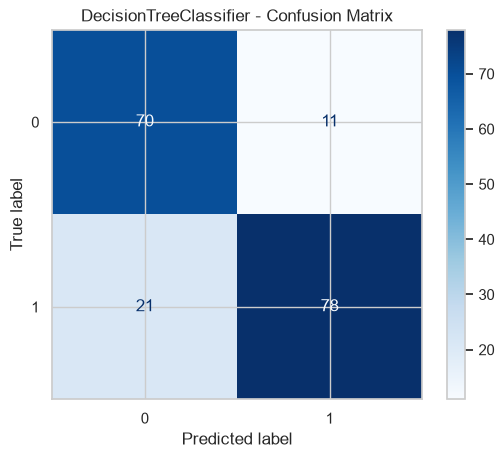

              precision    recall  f1-score   support

           0       0.89      0.80      0.84        81
           1       0.85      0.92      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.87      0.87       180



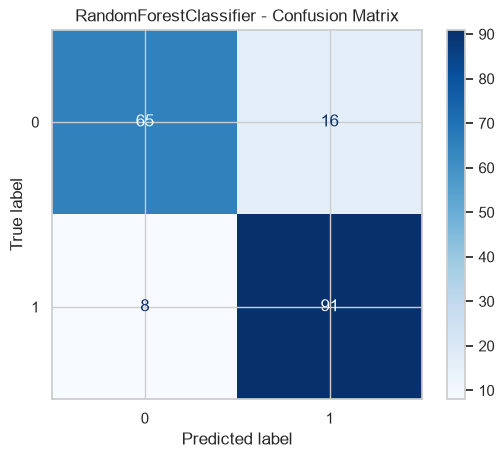

,Accuracy,Precision,Recall,F1-score,Training Time (s),Best CV F1
KNN,0.894444,0.892157,0.919192,0.905473,0.008806,0.893213
Logistic Regression,0.877778,0.873786,0.909091,0.891089,0.018909,0.881241
Decision Tree,0.822222,0.876404,0.787879,0.829787,0.011031,0.849248
Random Forest,0.866667,0.850467,0.919192,0.883495,0.659013,0.889666


In [51]:
tuned_models = {
    "KNN": knn_grid.best_estimator_,
    "Logistic Regression": lr_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_
}
tuned_before_results = {}
for name, model in tuned_models.items():
    metrics, pred = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test)
    tuned_before_results[name] = {**metrics, "Best CV F1": {
        "KNN": knn_grid.best_score_,
        "Logistic Regression": lr_grid.best_score_,
        "Decision Tree": dt_grid.best_score_,
        "Random Forest": rf_grid.best_score_
    }[name]}
tuned_before_df = pd.DataFrame(tuned_before_results).T
display(tuned_before_df)

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> **Answer:** Compare the tuned test metrics in `tuned_before_df` with the default results in Task 5. Tuning does not necessarily improve every model: cross-validation selects parameters that perform well on the training folds, but the held-out test result can stay the same or decline. The model with the largest positive change in the chosen metric (F1-score here) benefited the most. Differences can arise from the dataset size, split and how well each model's parameter grid matches the data.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

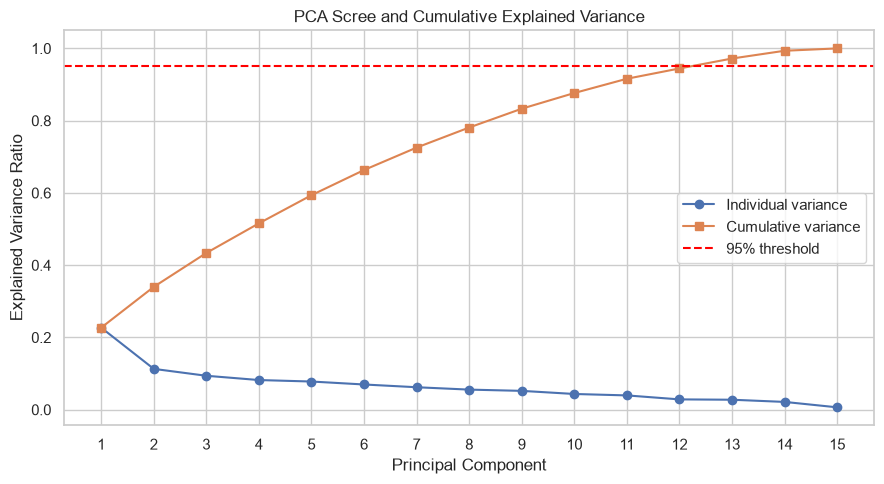

In [52]:
pca_all = PCA()
pca_all.fit(X_train_scaled)
explained_variance = pca_all.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker="o", label="Individual variance")
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="s", label="Cumulative variance")
plt.axhline(0.95, color="red", linestyle="--", label="95% threshold")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree and Cumulative Explained Variance")
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [53]:
n_components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print("Components required for at least 95% variance:", n_components_95)
print("Cumulative variance retained:", cumulative_variance[n_components_95 - 1])

Components required for at least 95% variance: 13
Cumulative variance retained: 0.9720332875516529


### 7.3 Transform the training and testing sets

In [54]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)  # Fit PCA ONLY on training data
X_test_pca = pca.transform(X_test_scaled)
print("Original feature count:", X_train_scaled.shape[1])
print("PCA component count:", X_train_pca.shape[1])
print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)
reduction_pct = (1 - X_train_pca.shape[1] / X_train_scaled.shape[1]) * 100
print(f"Feature-count reduction: {reduction_pct:.2f}%")

Original feature count: 15
PCA component count: 13
Training shape after PCA: (719, 13)
Testing shape after PCA: (180, 13)
Feature-count reduction: 13.33%


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

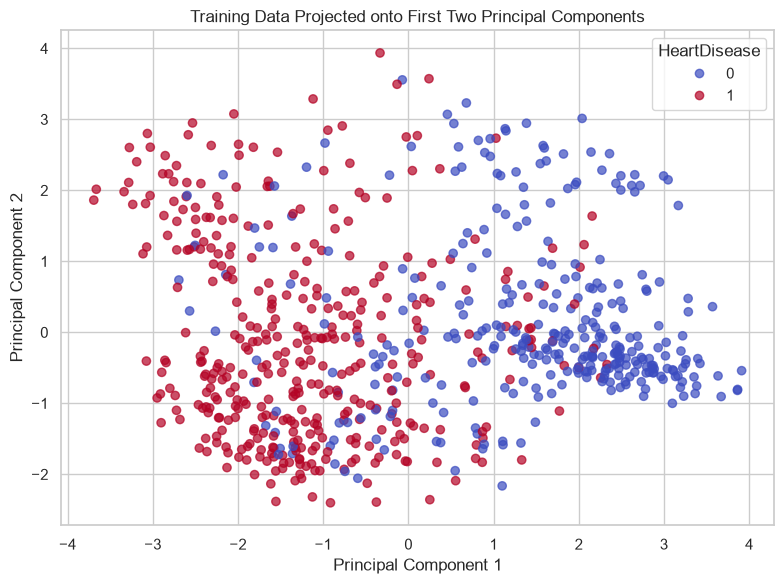

In [55]:
# Optional 2D visualisation (uses the first two principal components).
pca_2d = PCA(n_components=2)
X_train_2d = pca_2d.fit_transform(X_train_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Training Data Projected onto First Two Principal Components")
plt.legend(*scatter.legend_elements(), title="HeartDisease")
plt.tight_layout()
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> **Answer:** The exact number of components required to retain at least 95% of the variance is printed in Task 7.2 and is also represented by `X_train_pca.shape[1]` in Task 7.3. The percentage reduction in feature count is calculated as `(1 − number of PCA components / original number of encoded features) × 100`. Use the printed `Feature-count reduction` value for the numerical result.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

Best parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best mean CV F1-score: 0.8884393825845323
              precision    recall  f1-score   support

           0       0.91      0.89      0.90        81
           1       0.91      0.93      0.92        99

    accuracy                           0.91       180
   macro avg       0.91      0.91      0.91       180
weighted avg       0.91      0.91      0.91       180



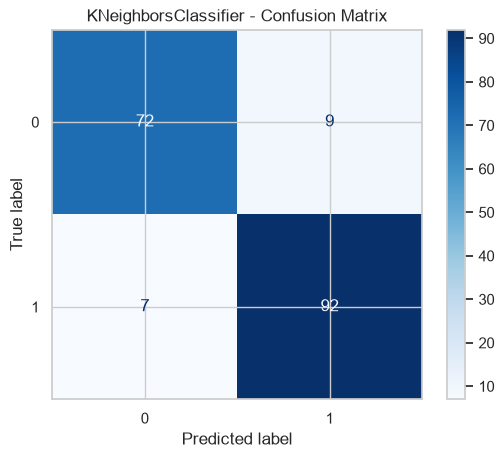

{'Accuracy': 0.9111111111111111, 'Precision': 0.9108910891089109, 'Recall': 0.9292929292929293, 'F1-score': 0.92, 'Training Time (s)': 0.005265499996312428}


In [56]:
# Tune and evaluate KNN using PCA-transformed features
knn_pca_grid = GridSearchCV(
    model_factories["KNN"](),
    param_grids["KNN"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
knn_pca_grid.fit(X_train_pca, y_train)
print("Best parameters:", knn_pca_grid.best_params_)
print("Best mean CV F1-score:", knn_pca_grid.best_score_)
knn_pca_metrics, knn_pca_pred = evaluate_model(
    knn_pca_grid.best_estimator_, X_train_pca, X_test_pca, y_train, y_test
)
print(knn_pca_metrics)

### 8.2 Logistic Regression after PCA

Best parameters: {'C': 0.1, 'solver': 'liblinear'}
Best mean CV F1-score: 0.8811501882019146
              precision    recall  f1-score   support

           0       0.87      0.85      0.86        81
           1       0.88      0.90      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



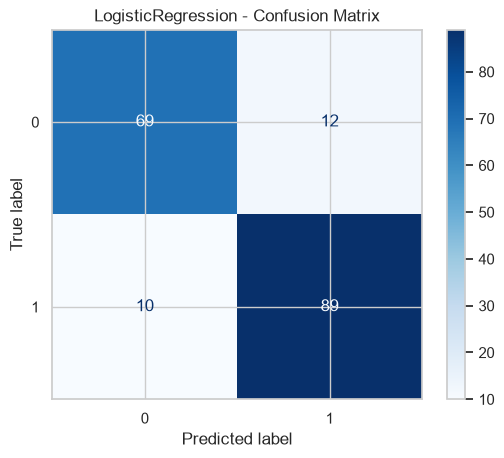

{'Accuracy': 0.8777777777777778, 'Precision': 0.8811881188118812, 'Recall': 0.898989898989899, 'F1-score': 0.89, 'Training Time (s)': 0.005288499996822793}


In [57]:
# Tune and evaluate Logistic Regression using PCA-transformed features
lr_pca_grid = GridSearchCV(
    model_factories["Logistic Regression"](),
    param_grids["Logistic Regression"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
lr_pca_grid.fit(X_train_pca, y_train)
print("Best parameters:", lr_pca_grid.best_params_)
print("Best mean CV F1-score:", lr_pca_grid.best_score_)
lr_pca_metrics, lr_pca_pred = evaluate_model(
    lr_pca_grid.best_estimator_, X_train_pca, X_test_pca, y_train, y_test
)
print(lr_pca_metrics)

### 8.3 Decision Tree after PCA

Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best mean CV F1-score: 0.8523042953251683
              precision    recall  f1-score   support

           0       0.86      0.85      0.86        81
           1       0.88      0.89      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



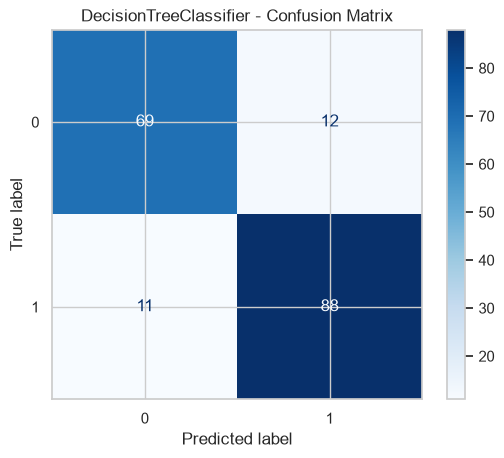

{'Accuracy': 0.8722222222222222, 'Precision': 0.88, 'Recall': 0.8888888888888888, 'F1-score': 0.8844221105527639, 'Training Time (s)': 0.015187500001047738}


In [58]:
# Tune and evaluate Decision Tree using PCA-transformed features
dt_pca_grid = GridSearchCV(
    model_factories["Decision Tree"](),
    param_grids["Decision Tree"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
dt_pca_grid.fit(X_train_pca, y_train)
print("Best parameters:", dt_pca_grid.best_params_)
print("Best mean CV F1-score:", dt_pca_grid.best_score_)
dt_pca_metrics, dt_pca_pred = evaluate_model(
    dt_pca_grid.best_estimator_, X_train_pca, X_test_pca, y_train, y_test
)
print(dt_pca_metrics)

### 8.4 Random Forest after PCA

Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best mean CV F1-score: 0.8838181270701595
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        81
           1       0.88      0.93      0.91        99

    accuracy                           0.89       180
   macro avg       0.90      0.89      0.89       180
weighted avg       0.90      0.89      0.89       180



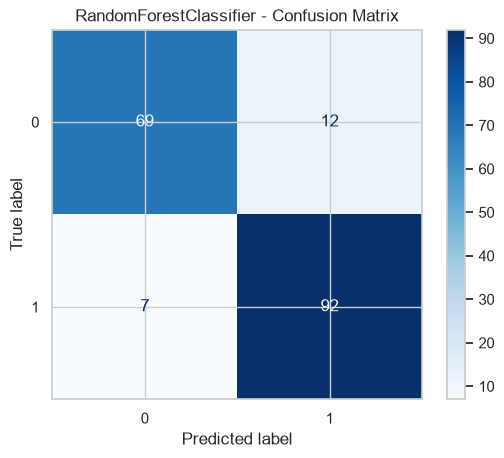

{'Accuracy': 0.8944444444444445, 'Precision': 0.8846153846153846, 'Recall': 0.9292929292929293, 'F1-score': 0.9064039408866995, 'Training Time (s)': 0.7647959999958402}


In [59]:
# Tune and evaluate Random Forest using PCA-transformed features
rf_pca_grid = GridSearchCV(
    model_factories["Random Forest"](),
    param_grids["Random Forest"],
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    refit=True
)
rf_pca_grid.fit(X_train_pca, y_train)
print("Best parameters:", rf_pca_grid.best_params_)
print("Best mean CV F1-score:", rf_pca_grid.best_score_)
rf_pca_metrics, rf_pca_pred = evaluate_model(
    rf_pca_grid.best_estimator_, X_train_pca, X_test_pca, y_train, y_test
)
print(rf_pca_metrics)

### 8.5 Comparison table of all four models after PCA

In [60]:
pca_model_grids = {
    "KNN": knn_pca_grid,
    "Logistic Regression": lr_pca_grid,
    "Decision Tree": dt_pca_grid,
    "Random Forest": rf_pca_grid
}
pca_model_metrics = {
    "KNN": knn_pca_metrics,
    "Logistic Regression": lr_pca_metrics,
    "Decision Tree": dt_pca_metrics,
    "Random Forest": rf_pca_metrics
}
pca_results = pd.DataFrame({
    name: {**metrics, "Best CV F1": pca_model_grids[name].best_score_}
    for name, metrics in pca_model_metrics.items()
}).T
display(pca_results)

,Accuracy,Precision,Recall,F1-score,Training Time (s),Best CV F1
KNN,0.911111,0.910891,0.929293,0.920000,0.005265,0.888439
Logistic Regression,0.877778,0.881188,0.898990,0.890000,0.005288,0.881150
Decision Tree,0.872222,0.880000,0.888889,0.884422,0.015188,0.852304
Random Forest,0.894444,0.884615,0.929293,0.906404,0.764796,0.883818


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> **Answer:** The best model after PCA is the model with the highest test metric in `pca_results` (consider F1-score and recall as well as accuracy). Compare its name and scores with `tuned_before_df` to determine whether it is also the best model before PCA. The winning model can differ because PCA changes the feature representation and may remove information useful to some classifiers.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features,No. of Features After PCA
KNN,0.894444,0.911111,0.905473,0.920000,0.008806,0.005265,15,13
Logistic Regression,0.877778,0.877778,0.891089,0.890000,0.018909,0.005288,15,13
Decision Tree,0.822222,0.872222,0.829787,0.884422,0.011031,0.015188,15,13
Random Forest,0.866667,0.894444,0.883495,0.906404,0.659013,0.764796,15,13


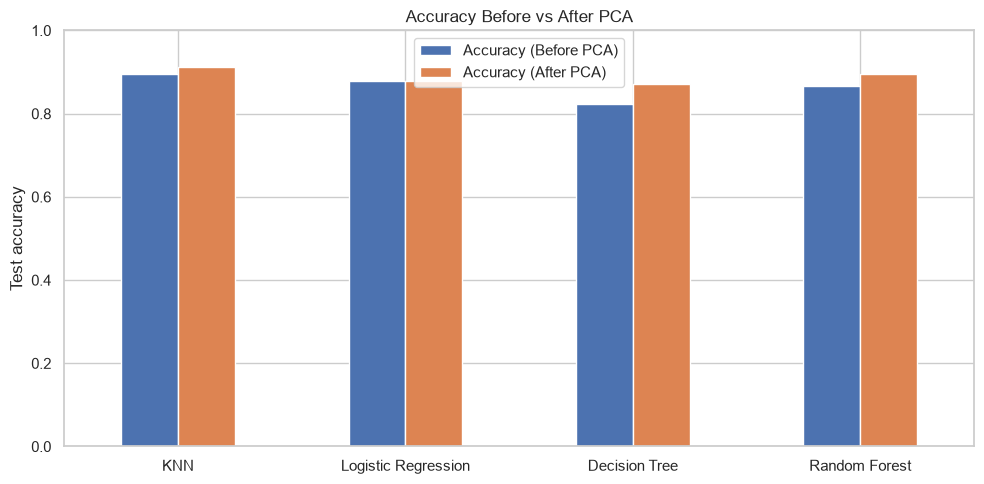

In [61]:
before = tuned_before_df.copy()
after = pca_results.copy()
comparison = pd.DataFrame(index=before.index)
comparison["Accuracy (Before PCA)"] = before["Accuracy"]
comparison["Accuracy (After PCA)"] = after["Accuracy"]
comparison["F1 (Before PCA)"] = before["F1-score"]
comparison["F1 (After PCA)"] = after["F1-score"]
comparison["Training Time Before (s)"] = before["Training Time (s)"]
comparison["Training Time After (s)"] = after["Training Time (s)"]
comparison["No. of Features"] = [X_train_scaled.shape[1]] * len(comparison)
comparison["No. of Features After PCA"] = [X_train_pca.shape[1]] * len(comparison)
display(comparison)
comparison[["Accuracy (Before PCA)", "Accuracy (After PCA)"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.ylabel("Test accuracy")
plt.title("Accuracy Before vs After PCA")
plt.tight_layout()
plt.show()

### 9.2 Visualise the before vs after PCA comparison

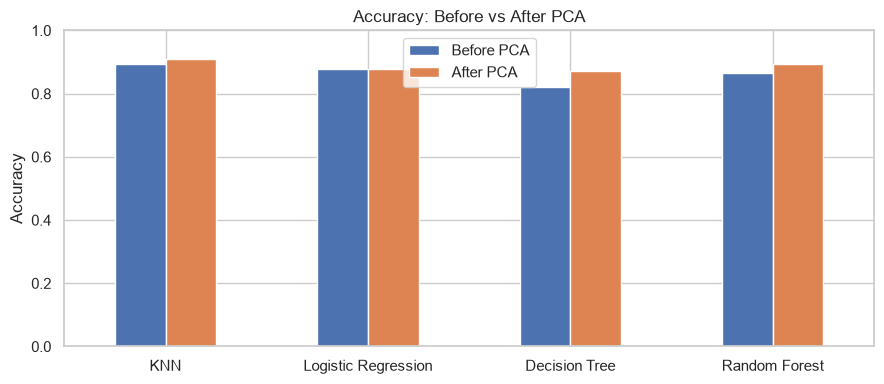

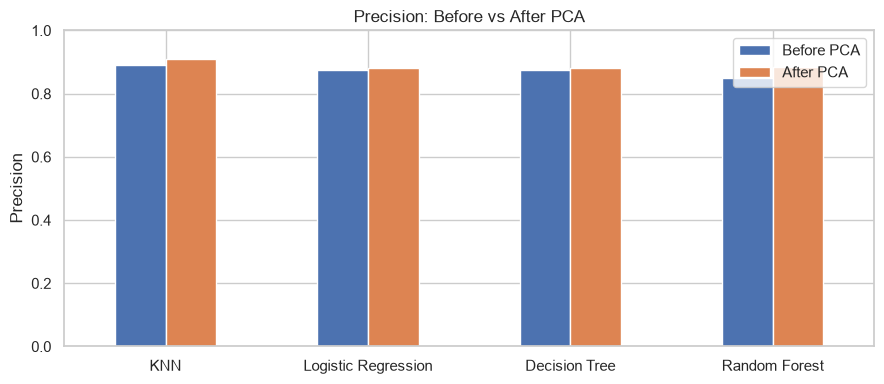

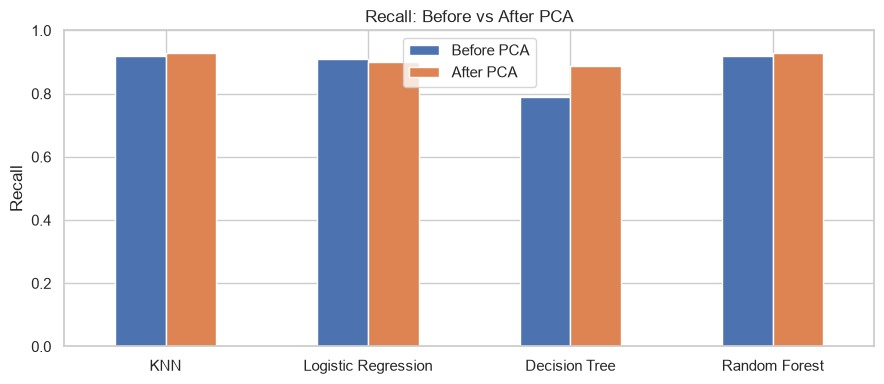

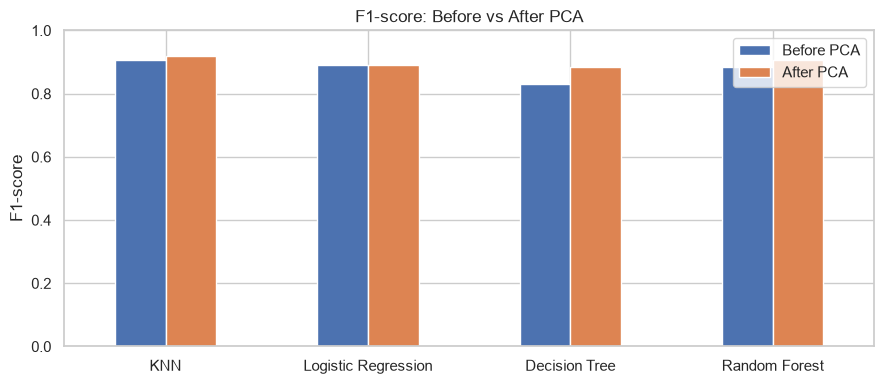

In [62]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
for metric in metrics_to_plot:
    plot_df = pd.DataFrame({
        "Before PCA": tuned_before_df[metric],
        "After PCA": pca_results[metric]
    })
    plot_df.plot(kind="bar", figsize=(9, 4), ylim=(0, 1), rot=0)
    plt.ylabel(metric)
    plt.title(f"{metric}: Before vs After PCA")
    plt.tight_layout()
    plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> **Answer:** Compare the before- and after-PCA columns in the consolidated table. A model improved if its after-PCA score is higher; it declined if the after-PCA score is lower. The exact outcome is dataset- and split-dependent, so use the measured Accuracy and F1 values rather than assuming PCA improves every classifier.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> **Answer:** PCA reduces the number of input features, which can reduce memory use and the computational cost of fitting and predicting, particularly for algorithms affected by the number of dimensions. However, fitting PCA itself adds preprocessing cost. The measured training times in the comparison table show the net effect for this experiment. A smaller feature space does not guarantee faster execution for every model or dataset.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> **Answer:** PCA may improve performance by removing correlated or noisy directions, but it may reduce performance if useful class-related information is discarded. KNN and Logistic Regression can respond noticeably to the transformed geometry. Decision Trees and Random Forests split on individual feature thresholds, so PCA can make their input less directly interpretable and sometimes less suitable. The result should be judged from the test metrics in this experiment, not from a general assumption that dimensionality reduction always helps.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> **Answer:** Using all features can preserve information and may give the best predictive performance, but it can increase computation and complexity. PCA offers a compact representation and may improve efficiency, but components are combinations of original features and are less interpretable. Prefer PCA when the feature space is large or computational constraints are important and validation shows that performance remains acceptable. Prefer the original features when interpretability or the strongest validated predictive performance is more important. In healthcare, these models are educational decision-support experiments and must not be used as a standalone clinical diagnosis system.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.